# Solution: Mission 01 — Customer Purchase Data Clinic

This notebook is one possible solution. Try the mission yourself before you read it.

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent.parent / "tools"))
import datasets

def load_purchases() -> pd.DataFrame:
    """Real Chinook purchases (one row per invoice line), exported from the SQLite file."""
    with sqlite3.connect(datasets.fetch("chinook.sqlite")) as con:
        return pd.read_sql("""
            SELECT il.InvoiceLineId AS line_id, i.InvoiceId AS invoice_id, i.InvoiceDate AS invoice_date,
                   c.CustomerId AS customer_id, c.Email AS email, c.Country AS country,
                   il.TrackId AS track_id, il.UnitPrice AS unit_price, il.Quantity AS quantity
            FROM InvoiceLine il JOIN Invoice i USING (InvoiceId) JOIN Customer c USING (CustomerId)""", con)

def break_like_three_systems(df: pd.DataFrame, seed: int = 8) -> pd.DataFrame:
    """Add the typical errors of three export systems (documented, seeded, reproducible)."""
    rng = np.random.default_rng(seed)
    out = df.copy()
    n = len(out)
    dates = pd.to_datetime(out["invoice_date"])
    fmt = rng.choice(["iso", "eu", "us"], n, p=[0.6, 0.25, 0.15])            # system A: ISO, B: day.month, C: month/day
    out["invoice_date"] = np.select([fmt == "iso", fmt == "eu"],
                                    [dates.dt.strftime("%Y-%m-%d"), dates.dt.strftime("%d.%m.%Y")],
                                    dates.dt.strftime("%m/%d/%Y"))
    out["source_system"] = np.select([fmt == "iso", fmt == "eu"], ["A", "B"], "C")
    variants = {"USA": ["USA", "usa", "United States", " U.S.A. "], "United Kingdom": ["United Kingdom", "UK", "united kingdom"],
                "Brazil": ["Brazil", "Brasil", "brazil "]}
    out["country"] = [rng.choice(variants[c]) if c in variants else c for c in out["country"]]
    upper = rng.random(n) < 0.2
    out.loc[upper, "email"] = "  " + out.loc[upper, "email"].str.upper()
    out["unit_price"] = out["unit_price"].astype(object)
    out.loc[rng.random(n) < 0.05, "unit_price"] = None                       # missing prices
    comma = (rng.random(n) < 0.03) & out["unit_price"].notna()
    out.loc[comma, "unit_price"] = out.loc[comma, "unit_price"].map(lambda p: f"{p:.2f}".replace(".", ","))  # system B
    out.loc[rng.random(n) < 0.01, "quantity"] = -1                           # sign errors
    dup = out.sample(frac=0.04, random_state=seed)                           # re-sent records
    return pd.concat([out, dup]).sample(frac=1, random_state=seed).reset_index(drop=True)

clean_truth = load_purchases()
raw = break_like_three_systems(clean_truth)
print(f"{len(raw):,} raw rows from three systems")
raw.head()

2,330 raw rows from three systems


,line_id,invoice_id,invoice_date,customer_id,email,country,track_id,unit_price,quantity,source_system
0,1609,298,2012-07-31,17,jacksmith@microsoft.com,usa,2780,0.99,1,A
1,1104,204,2011-06-19,42,wyatt.girard@yahoo.fr,France,3229,1.99,1,A
2,167,32,2009-05-10,48,johavanderberg@yahoo.nl,Netherlands,982,0.99,1,A
3,1406,259,22.02.2012,49,stanisław.wójcik@wp.pl,Poland,1578,0.99,1,B
4,266,49,2009-08-06,30,EDFRANCIS@YACHOO.CA,Canada,1624,"0,99",1,A


## Task 1: Profile

In [2]:
print(raw.dtypes, "\n")
print("missing values:", raw.isna().sum()[raw.isna().sum() > 0].to_dict())
print("exact duplicate rows:", raw.duplicated().sum(), "| duplicate line_id:", raw["line_id"].duplicated().sum())
print("country spellings:", sorted(raw["country"].unique())[:12], "...")
print("date examples per system:", raw.groupby("source_system")["invoice_date"].first().to_dict())

line_id           int64
invoice_id        int64
invoice_date        str
customer_id       int64
email               str
country             str
track_id          int64
unit_price       object
quantity          int64
source_system       str
dtype: object 

missing values: {'unit_price': 99}
exact duplicate rows: 90 | duplicate line_id: 90
country spellings: [' U.S.A. ', 'Argentina', 'Australia', 'Austria', 'Belgium', 'Brasil', 'Brazil', 'Canada', 'Chile', 'Czech Republic', 'Denmark', 'Finland'] ...
date examples per system: {'A': '2012-07-31', 'B': '22.02.2012', 'C': '04/09/2009'}


## Tasks 2–5: Clean with Named Rules

In [3]:
COUNTRY = {"usa": "USA", "united states": "USA", "u.s.a.": "USA", "uk": "United Kingdom",
           "united kingdom": "United Kingdom", "brasil": "Brazil", "brazil": "Brazil"}
DATE_FORMAT = {"A": "%Y-%m-%d", "B": "%d.%m.%Y", "C": "%m/%d/%Y"}
log = []

def step(name: str, before: pd.DataFrame, after: pd.DataFrame, changed: int) -> pd.DataFrame:
    log.append({"rule": name, "rows_changed": int(changed), "rows_after": len(after)})
    return after

df = raw.copy()
parsed = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
for system, fmt in DATE_FORMAT.items():
    m = df["source_system"] == system
    parsed[m] = pd.to_datetime(df.loc[m, "invoice_date"], format=fmt)
df = step("parse dates per system", df, df.assign(invoice_date=parsed), len(df))

email = df["email"].str.strip().str.lower()
df = step("trim and lower e-mail", df, df.assign(email=email), (email != df["email"]).sum())

key = df["country"].str.strip().str.lower()
country = key.map(COUNTRY).fillna(df["country"].str.strip())
df = step("standardise country", df, df.assign(country=country), (country != df["country"]).sum())

price = pd.to_numeric(df["unit_price"].astype("str").str.replace(",", ".", regex=False), errors="coerce")
price[df["unit_price"].isna()] = np.nan
df = step("decimal comma -> number", df, df.assign(unit_price=price), df["unit_price"].astype("str").str.contains(",").sum())

track_median = df.groupby("track_id")["unit_price"].transform("median")
filled = df["unit_price"].fillna(track_median).fillna(df["unit_price"].median())
df = step("impute price by track median", df, df.assign(unit_price=filled), df["unit_price"].isna().sum())

qty = df["quantity"].abs()          # a negative quantity is a sign error: Chinook sells single tracks, no returns
df = step("fix negative quantity", df, df.assign(quantity=qty), (df["quantity"] < 0).sum())

dedup = df.drop_duplicates(subset="line_id", keep="first")
df = step("remove re-sent records", df, dedup, len(df) - len(dedup))
clean = df.sort_values("line_id").reset_index(drop=True)
pd.DataFrame(log)

,rule,rows_changed,rows_after
0,parse dates per system,2330,2330
1,trim and lower e-mail,418,2330
2,standardise country,600,2330
3,decimal comma -> number,67,2330
4,impute price by track median,99,2330
5,fix negative quantity,22,2330
6,remove re-sent records,90,2240


## Task 6: Validate and Compare with the Truth

In [4]:
assert clean["line_id"].is_unique
assert clean["invoice_date"].notna().all() and (clean["quantity"] > 0).all() and clean["unit_price"].notna().all()
assert set(clean["country"]) == set(clean_truth["country"]), "unknown country spelling left"

truth = clean_truth.sort_values("line_id").reset_index(drop=True)
rev_clean = float((clean["unit_price"] * clean["quantity"]).sum())
rev_truth = float((truth["unit_price"] * truth["quantity"]).sum())
print(f"rows: {len(clean):,} vs truth {len(truth):,}")
print(f"revenue: {rev_clean:,.2f} vs truth {rev_truth:,.2f} (difference {rev_clean - rev_truth:+.2f})")
print(f"exactly matching prices: {(np.isclose(clean['unit_price'], truth['unit_price'])).mean():.2%}")
print(f"dates equal to the truth: {(clean['invoice_date'] == pd.to_datetime(truth['invoice_date'])).mean():.2%}")

rows: 2,240 vs truth 2,240
revenue: 2,326.60 vs truth 2,328.60 (difference -2.00)
exactly matching prices: 99.91%
dates equal to the truth: 100.00%


The track-median imputation recovers almost all prices exactly, because every track has one fixed price in Chinook. Any remaining difference comes from tracks that were sold only once and whose only price was missing: for them, the global median is a guess.

## Task 7: Customer Summary

59 customers
                    country first_purchase last_purchase  invoices  revenue  \
customer_id                                                                   
6            Czech Republic     2009-07-11    2013-11-13         7    49.62   
26                      USA     2009-11-07    2013-04-05         7    47.62   
57                    Chile     2009-04-04    2012-10-14         7    46.62   
45                  Hungary     2010-01-08    2013-07-20         7    45.62   
46                  Ireland     2009-02-03    2013-11-04         7    45.62   
37                  Germany     2009-01-19    2013-06-03         7    43.62   
24                      USA     2010-02-08    2013-08-20         7    43.62   
7                   Austria     2009-12-08    2013-06-19         7    42.62   
25                      USA     2009-03-06    2013-12-05         7    42.62   
28                      USA     2009-11-07    2013-05-19         7    42.62   

             avg_invoice  
customer_id

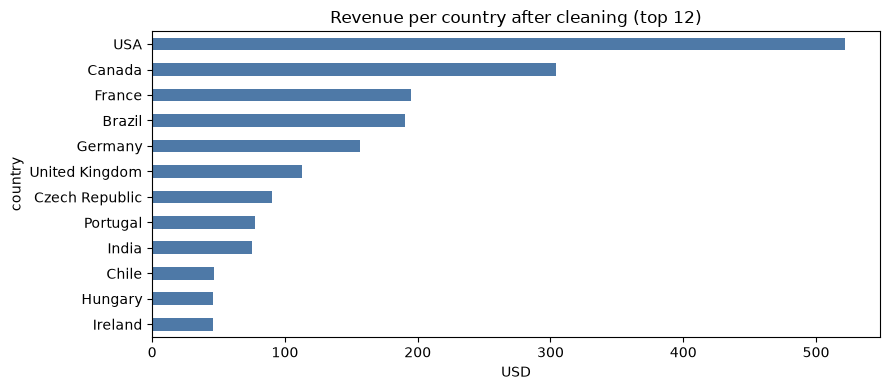

In [5]:
clean["revenue"] = clean["unit_price"] * clean["quantity"]
customers = (clean.groupby("customer_id")
             .agg(country=("country", "first"), email=("email", "first"),
                  first_purchase=("invoice_date", "min"), last_purchase=("invoice_date", "max"),
                  invoices=("invoice_id", "nunique"), revenue=("revenue", "sum"))
             .assign(avg_invoice=lambda d: d["revenue"] / d["invoices"])
             .sort_values("revenue", ascending=False))
print(f"{len(customers)} customers")
print(customers.head(10).round({"revenue": 2, "avg_invoice": 2}).drop(columns="email"))

fig, ax = plt.subplots(figsize=(9, 4))
customers.groupby("country")["revenue"].sum().sort_values().tail(12).plot.barh(ax=ax, color="#4E79A7")
ax.set(title="Revenue per country after cleaning (top 12)", xlabel="USD")
plt.tight_layout()
plt.show()